# 02 - SQL Analysis

The queries are written in `../sql/analysis_queries.sql` (one file, easy to read on GitHub).
This notebook runs each one against the SQLite database made in notebook 01 and says what the result means.

**Why SQL for this step?** Almost every business has its data in a database, so aggregating with
`GROUP BY`, `CASE WHEN` and window functions is the core daily skill of a data analyst.
Pandas could also do this, but here SQL is the tool being demonstrated.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/superstore.db")

# The .sql file holds many queries. Each one is introduced by a line that starts with "-- name:".
sql_text = open("../sql/analysis_queries.sql").read()
queries = {}
for block in sql_text.split("-- name:")[1:]:
    name, query = block.split("\n", 1)
    queries[name.strip()] = query.strip()


def run(name, params=()):
    return pd.read_sql_query(queries[name], conn, params=params)


print(len(queries), "queries loaded")

20 queries loaded


## 1. How big is the business, and is it profitable?

*Average order value = total revenue / number of distinct orders.* I count distinct `order_id`
because one order has several lines, and counting rows would overstate the number of orders.

In [2]:
run("kpis")

,total_revenue,total_profit,total_orders,avg_order_value,profit_margin_pct
0,2297200.86,286397.02,5009,458.61,12.47


**Result:** about 2.30M in revenue and 286K in profit on 5,009 orders. That is a 12.5% profit margin
and an average order value of 458.61. The business is profitable overall, so the interesting question is
*where* it makes and loses money.

## 2. Year-over-year performance

`LAG()` is a window function: it reads the previous row (the previous year) so growth can be calculated in
the same query. It is the SQL version of Excel's "compare with the cell above".

In [3]:
run("yearly")

,year,revenue,profit,orders,margin_pct,revenue_growth_pct
0,2015,484247.0,49544.0,969,10.2,NaN
1,2016,470533.0,61619.0,1038,13.1,-2.8
2,2017,609206.0,81795.0,1315,13.4,29.5
3,2018,733215.0,93439.0,1687,12.7,20.4


**Result:** revenue dipped 2.8% in 2016, then grew 29.5% in 2017 and 20.4% in 2018.
Profit grew faster than revenue from 2015 to 2018 (+89% vs +51%) but **not in 2018**: revenue +20.4%, profit
only +14.2%, and margin fell from 13.4% to 12.7%. Something took profit away in 2018. Section 6 shows what.

## 3. Monthly trend and seasonality

In [4]:
monthly = run("monthly")
monthly.tail(6)

,month,revenue,profit,orders
42,2018-07,45264.0,6953.0,111
43,2018-08,63121.0,9041.0,111
44,2018-09,87867.0,10992.0,226
45,2018-10,77777.0,9275.0,147
46,2018-11,118448.0,9690.0,261
47,2018-12,83829.0,8483.0,224


In [5]:
run("seasonality")

,month_number,avg_monthly_revenue
0,01,23731.0
1,02,14938.0
2,03,51251.0
3,04,34441.0
4,05,38757.0
5,06,38180.0
6,07,36810.0
7,08,39761.0
8,09,76912.0
9,10,50081.0


**Result:** the business is very seasonal. On average September, November and December bring
42.9% of a year's revenue (November alone averages 88K), while January and February together bring
only 6.7%. November 2018 was the biggest month in the data (118K).

## 4. Categories and sub-categories

In [6]:
run("category")

,category,revenue,profit,margin_pct,revenue_share_pct
0,Technology,836154.0,145455.0,17.4,36.4
1,Furniture,742000.0,18451.0,2.5,32.3
2,Office Supplies,719047.0,122491.0,17.0,31.3


In [7]:
run("sub_category")

,category,sub_category,revenue,profit,margin_pct,avg_discount_pct
0,Furniture,Tables,206966.0,-17725.0,-8.6,26.1
1,Furniture,Bookcases,114880.0,-3473.0,-3.0,21.1
2,Office Supplies,Supplies,46674.0,-1189.0,-2.5,7.7
3,Office Supplies,Fasteners,3024.0,950.0,31.4,8.2
4,Technology,Machines,189239.0,3385.0,1.8,30.6
5,Office Supplies,Labels,12486.0,5546.0,44.4,6.9
6,Office Supplies,Art,27119.0,6528.0,24.1,7.5
7,Office Supplies,Envelopes,16476.0,6964.0,42.3,8.0
8,Furniture,Furnishings,91705.0,13059.0,14.2,13.8
9,Office Supplies,Appliances,107532.0,18138.0,16.9,16.7


**Result:** Technology and Office Supplies earn a 17% margin. **Furniture sells almost as much as Technology
(742K vs 836K) but earns only 2.5% margin**: 18K profit from 32% of the revenue.
Three sub-categories lose money: **Tables (-17.7K)**, Bookcases (-3.5K) and Supplies (-1.2K).
Machines sell 189K but earn only 1.8% margin.

## 5. Regions and states

In [8]:
run("region")

,region,revenue,profit,margin_pct,orders,avg_discount_pct
0,West,725458.0,108418.0,14.9,1611,10.9
1,East,678781.0,91523.0,13.5,1401,14.5
2,Central,501240.0,39706.0,7.9,1175,24.0
3,South,391722.0,46749.0,11.9,822,14.7


In [9]:
run("state_losses")

,state,region,revenue,profit,avg_discount_pct
0,Texas,Central,170188.0,-25729.0,37.0
1,Ohio,East,78258.0,-16971.0,32.5
2,Pennsylvania,East,116512.0,-15560.0,32.9
3,Illinois,Central,80166.0,-12608.0,39.0
4,North Carolina,South,55603.0,-7491.0,28.4
5,Colorado,West,32108.0,-6528.0,31.6
6,Tennessee,South,30662.0,-5342.0,29.1
7,Arizona,West,35282.0,-3428.0,30.4
8,Florida,South,89474.0,-3399.0,29.9
9,Oregon,West,17431.0,-1190.0,28.9


**Result:** the West is the biggest and best region (14.9% margin). **Central has a 7.9% margin**, the lowest,
and also the highest average discount (24.0%). Ten states lose money, led by **Texas (-25.7K), Ohio (-17.0K),
Pennsylvania (-15.6K) and Illinois (-12.6K)**. Together they lose about 98K. All ten give average discounts
between 28% and 39%, compared with 15.6% for the whole company.

Q9 is a **parameterized query**: the `?` in `WHERE region = ?` is filled by the database driver. I never
paste user text into SQL strings, which is how SQL injection happens.

In [10]:
for region in ["West", "East", "Central", "South"]:
    print(region)
    print(run("region_worst_subcategories", params=(region,)).to_string(index=False))
    print()

West
sub_category  revenue  profit
   Bookcases  36004.0 -1647.0
    Machines  42444.0  -619.0
   Fasteners    923.0   275.0

East
sub_category  revenue   profit
      Tables  39140.0 -11025.0
   Bookcases  43819.0  -1168.0
    Supplies  10760.0  -1155.0

Central
sub_category  revenue  profit
 Furnishings  15254.0 -3906.0
      Tables  39155.0 -3560.0
  Appliances  23582.0 -2639.0

South
sub_category  revenue  profit
      Tables  43916.0 -4623.0
    Machines  53891.0 -1439.0
    Supplies   8319.0     2.0



## 6. The discount question

I group each order line by how much discount it received and compare profit. The bands are my own choice:
no discount, up to 20% (common promotions), 21-40% and over 40%.

In [11]:
run("discount_bands")

,discount_band,order_lines,revenue,profit,margin_pct
0,1) No discount,4798,1087908.0,320988.0,29.5
1,2) Up to 20%,3803,846522.0,100785.0,11.9
2,3) 21-40%,460,234138.0,-35817.0,-15.3
3,4) Over 40%,933,128632.0,-99559.0,-77.4


**Result:** this is the key table of the project.

| Discount | Margin |
|---|---|
| None | +29.5% |
| Up to 20% | +11.9% |
| 21-40% | -15.3% |
| Over 40% | -77.4% |

Lines discounted above 20% are only 13.9% of order lines and 15.8% of revenue, but they lose **135K** in
total, while all other lines earn 422K.

In [12]:
run("discount_by_category")

,category,margin_pct_up_to_20,margin_pct_over_20,profit_over_20
0,Furniture,13.3,-27.9,-54478.0
1,Office Supplies,25.0,-119.3,-47140.0
2,Technology,25.3,-26.4,-33758.0


In [13]:
run("deep_discount_subcategories")

,sub_category,lines_over_20,profit_over_20,profit_up_to_20
0,Binders,613,-38510.0,68732.0
1,Tables,176,-30698.0,12973.0
2,Machines,53,-29555.0,32940.0
3,Bookcases,70,-11098.0,7625.0
4,Appliances,67,-8630.0,26768.0
5,Chairs,158,-6737.0,33327.0


In [14]:
run("deep_discount_by_year")

,year,pct_lines_over_20,revenue_over_20,profit_over_20
0,2015,14.1,104325.0,-28044.0
1,2016,13.9,63983.0,-28405.0
2,2017,14.0,87100.0,-31357.0
3,2018,13.7,107362.0,-47570.0


**Result:**

- Deep discounts lose money in *every* category. **Furniture earns 13.3% margin on lines discounted up to
  20%** but loses 27.9% above 20%, which explains most of its weak 2.5% overall margin.
- **Binders** have 613 deep-discount lines (44% of all of them) and lose 38.5K on them, while the same
  sub-category earns 68.7K on lines discounted up to 20%.
- The *share* of heavily discounted lines is flat at about 14% every year, but the **loss on them rose from
  31.4K (2017) to 47.6K (2018), a 52% increase**. That matches the 2018 profit slowdown from section 2.

## 7. Products

In [15]:
run("top_products")

,product_name,revenue,profit,margin_pct
0,Canon imageCLASS 2200 Advanced Copier,61600.0,25200.0,40.9
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.0,7753.0,28.2
2,Cisco TelePresence System EX90 Videoconferenci...,22638.0,-1811.0,-8.0
3,HON 5400 Series Task Chairs for Big and Tall,21871.0,0.0,0.0
4,GBC DocuBind TL300 Electric Binding System,19823.0,2234.0,11.3
5,GBC Ibimaster 500 Manual ProClick Binding System,19025.0,761.0,4.0
6,Hewlett Packard LaserJet 3310 Copier,18840.0,6984.0,37.1
7,HP Designjet T520 Inkjet Large Format Printer ...,18375.0,4095.0,22.3
8,GBC DocuBind P400 Electric Binding System,17965.0,-1878.0,-10.5
9,High Speed Automatic Electric Letter Opener,17030.0,-262.0,-1.5


In [16]:
run("worst_products")

,product_name,revenue,profit,avg_discount_pct
0,Cubify CubeX 3D Printer Double Head Print,11100.0,-8880.0,53.3
1,Lexmark MX611dhe Monochrome Laser Printer,16830.0,-4590.0,40.0
2,Cubify CubeX 3D Printer Triple Head Print,8000.0,-3840.0,50.0
3,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9918.0,-2876.0,28.0
4,Bush Advantage Collection Racetrack Conference...,9545.0,-1934.0,35.0
5,GBC DocuBind P400 Electric Binding System,17965.0,-1878.0,45.0
6,Cisco TelePresence System EX90 Videoconferenci...,22638.0,-1811.0,50.0
7,Martin Yale Chadless Opener Electric Letter Op...,16656.0,-1299.0,10.0
8,Balt Solid Wood Round Tables,6519.0,-1201.0,20.0
9,BoxOffice By Design Rectangular and Half-Moon ...,1706.0,-1148.0,48.3


**Result:** the top 10 products make up 10.6% of revenue. Three of them lose money
(Cisco TelePresence EX90, GBC DocuBind P400 and a letter opener) and one breaks even. The two
Cubify CubeX 3D printers lose 12.7K together at average discounts of 50-53%.

## 8. Customers

`NTILE`-style ranking is not needed here: `ROW_NUMBER()` ranks customers by revenue, and a CTE (`WITH ...`)
keeps the "top 10% of customers" query readable.

In [17]:
run("segments")

,segment,customers,orders,revenue,profit,margin_pct
0,Consumer,409,2586,1161401.0,134119.0,11.5
1,Corporate,236,1514,706146.0,91979.0,13.0
2,Home Office,148,909,429653.0,60299.0,14.0


In [18]:
run("customer_frequency")

,order_count_group,customers
0,1 order,12
1,2-4 orders,183
2,5-8 orders,439
3,9+ orders,159


In [19]:
run("customer_concentration")

,total_customers,top_10pct_revenue_share
0,793,30.6


**Result:** there are 793 customers and almost all of them return: only 12 bought once, and
781 (98.5%) placed 2 or more orders (6.3 orders on average over four years). Revenue is not
concentrated: the top 10% of customers bring 30.6% of revenue. Consumers are half of revenue (50.6%) but have the
lowest margin (11.5%); Home Office is the smallest segment (18.7%) with the best margin (14.0%).

## 9. Returns

The data has a list of returned orders (no reason and no refund amount), so I measure the **return rate per
order** and the **sales value inside returned orders**. This is an upper limit on revenue at risk, not
the amount actually refunded.

In [20]:
run("returns")

,region,orders,returned_orders,return_rate_pct,sales_in_returned_orders
0,West,1611,189,11.7,107483.0
1,Central,1175,39,3.3,14007.0
2,East,1401,44,3.1,41705.0
3,South,822,24,2.9,17309.0


In [21]:
returns_by_year = run("returns_by_year")
returns_by_year.pivot(index="region", columns="year", values="return_rate_pct")

year,2015,2016,2017,2018
region,,,,
Central,3.5,3.8,2.3,3.7
East,3.8,3.4,2.9,2.8
South,3.0,2.9,3.7,2.2
West,9.6,10.9,12.1,13.2


**Result:** 296 of 5,009 orders (5.9%) were returned. **The West has an 11.7% return rate; every other region is
about 3%.** The West holds 64% of all returned orders, and its rate has risen every year (9.6% in 2015 to 13.2% in
2018). Returned orders contain 180.5K of sales, 7.9% of revenue.

## 10. Charts for the README

Simple matplotlib charts: one message each, one colour for profit and one for loss.

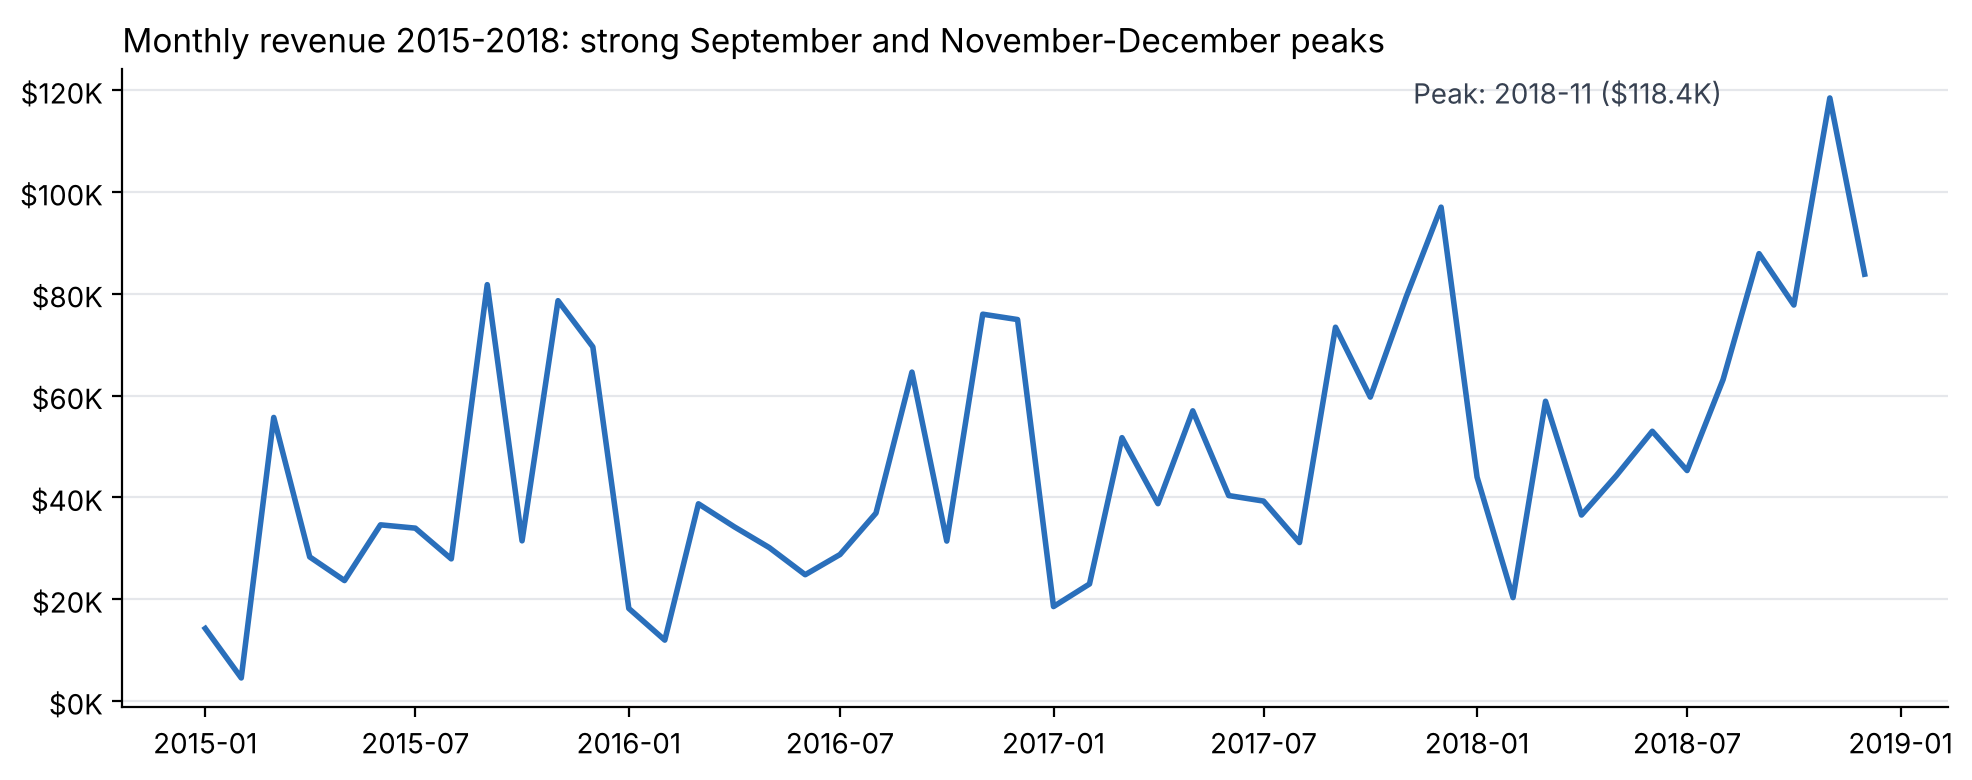

In [22]:
BLUE, ORANGE = "#2a6fbb", "#d4691e"


def money(value):
    sign = "-" if value < 0 else ""
    return f"{sign}${abs(value) / 1000:.1f}K"


def tidy(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e7eb", linewidth=0.8)
    ax.set_axisbelow(True)


# Chart 1: monthly revenue
fig, ax = plt.subplots(figsize=(10, 4))
months = pd.to_datetime(monthly["month"])
ax.plot(months, monthly["revenue"], color=BLUE, linewidth=2)
ax.yaxis.set_major_formatter(lambda x, _: f"${x / 1000:.0f}K")
peak = monthly.loc[monthly["revenue"].idxmax()]
ax.annotate(f"Peak: {peak['month']} ({money(peak['revenue'])})", (pd.to_datetime(peak["month"]), peak["revenue"]),
            xytext=(-150, -2), textcoords="offset points", color="#374151")
ax.set_title("Monthly revenue 2015-2018: strong September and November-December peaks", loc="left")
tidy(ax)
fig.tight_layout()
fig.savefig("../dashboard/analysis_monthly_revenue.png", dpi=150)
plt.show()

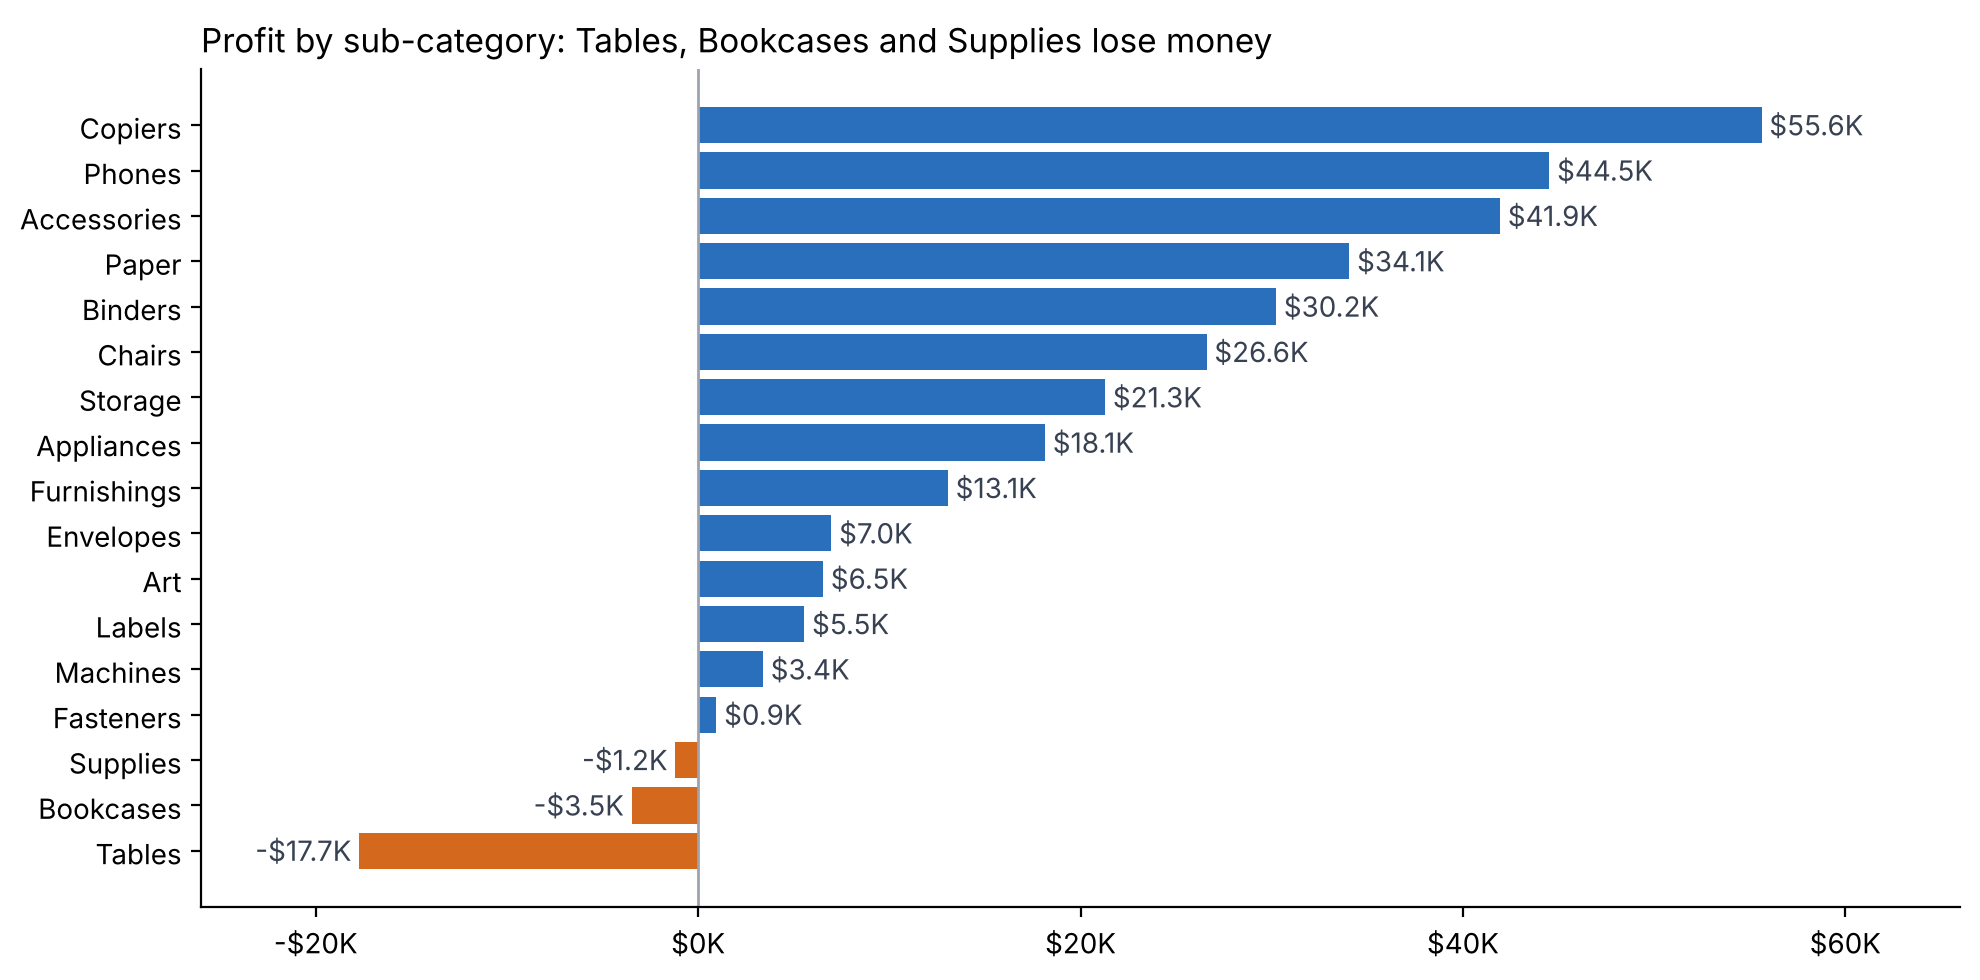

In [23]:
# Chart 2: profit by sub-category
sub = run("sub_category").sort_values("profit")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(sub["sub_category"], sub["profit"], color=[ORANGE if p < 0 else BLUE for p in sub["profit"]])
for y, p in enumerate(sub["profit"]):
    ax.text(p, y, f" {money(p)} ", va="center", ha="left" if p >= 0 else "right", color="#374151")
ax.axvline(0, color="#9ca3af", linewidth=1)
ax.xaxis.set_major_formatter(lambda x, _: money(x).replace(".0K", "K"))
ax.set_xlim(-26000, 66000)
ax.set_title("Profit by sub-category: Tables, Bookcases and Supplies lose money", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../dashboard/analysis_profit_by_subcategory.png", dpi=150)
plt.show()

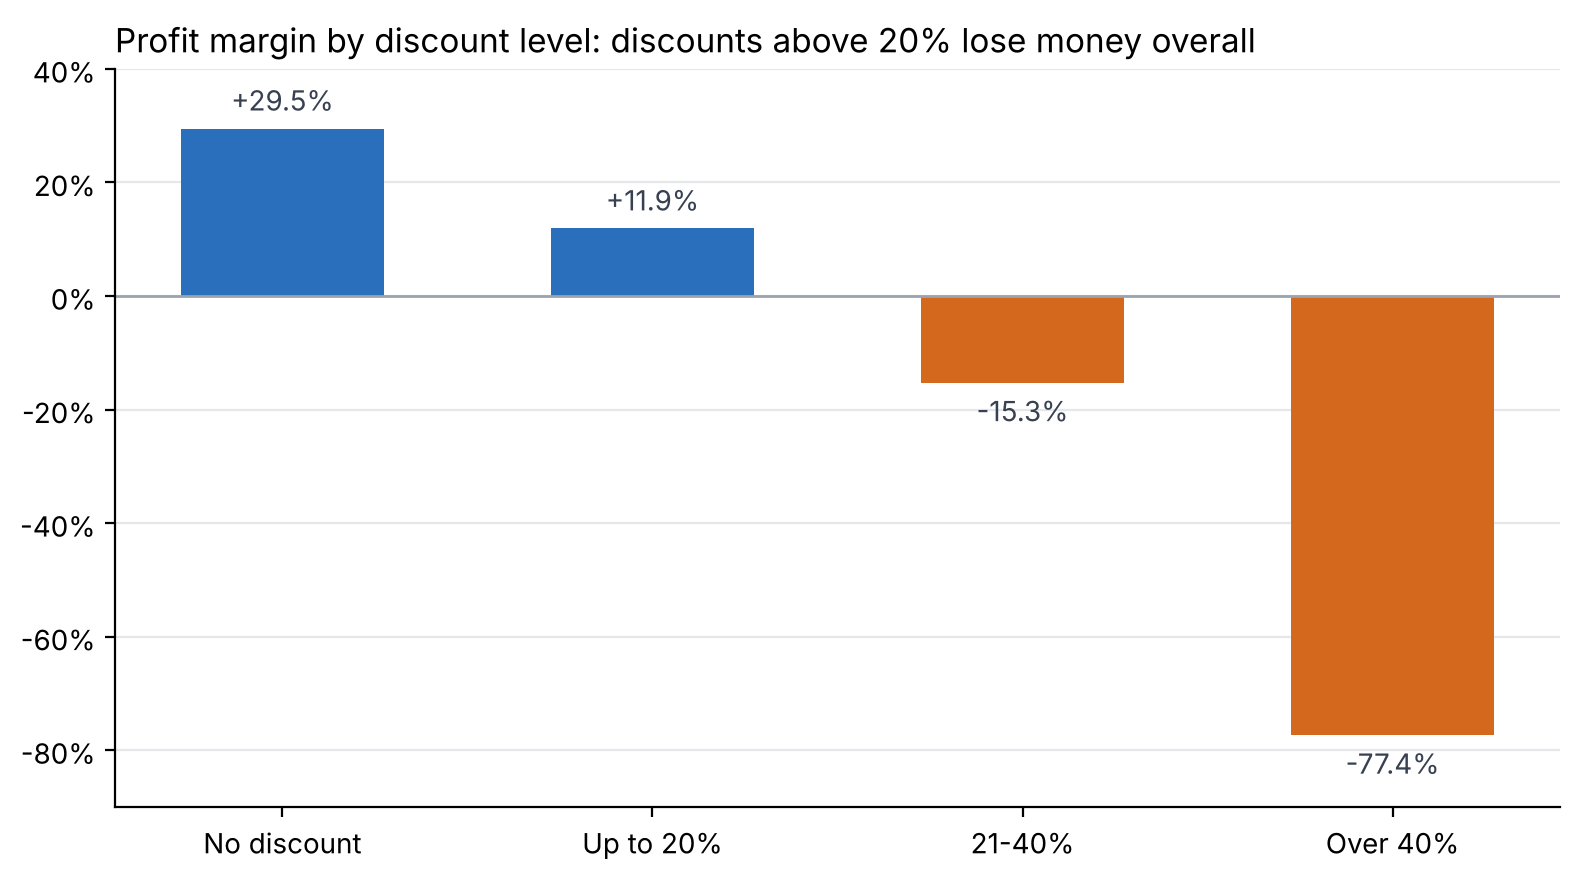

In [24]:
# Chart 3: margin by discount band
bands = run("discount_bands")
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = bands["discount_band"].str[3:]
ax.bar(labels, bands["margin_pct"], color=[ORANGE if m < 0 else BLUE for m in bands["margin_pct"]], width=0.55)
for x, m in enumerate(bands["margin_pct"]):
    ax.text(x, m + (2 if m >= 0 else -2), f"{m:+.1f}%", ha="center", va="bottom" if m >= 0 else "top", color="#374151")
ax.axhline(0, color="#9ca3af", linewidth=1)
ax.set_ylim(-90, 40)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0f}%")
ax.set_title("Profit margin by discount level: discounts above 20% lose money overall", loc="left")
tidy(ax)
fig.tight_layout()
fig.savefig("../dashboard/analysis_margin_by_discount.png", dpi=150)
plt.show()

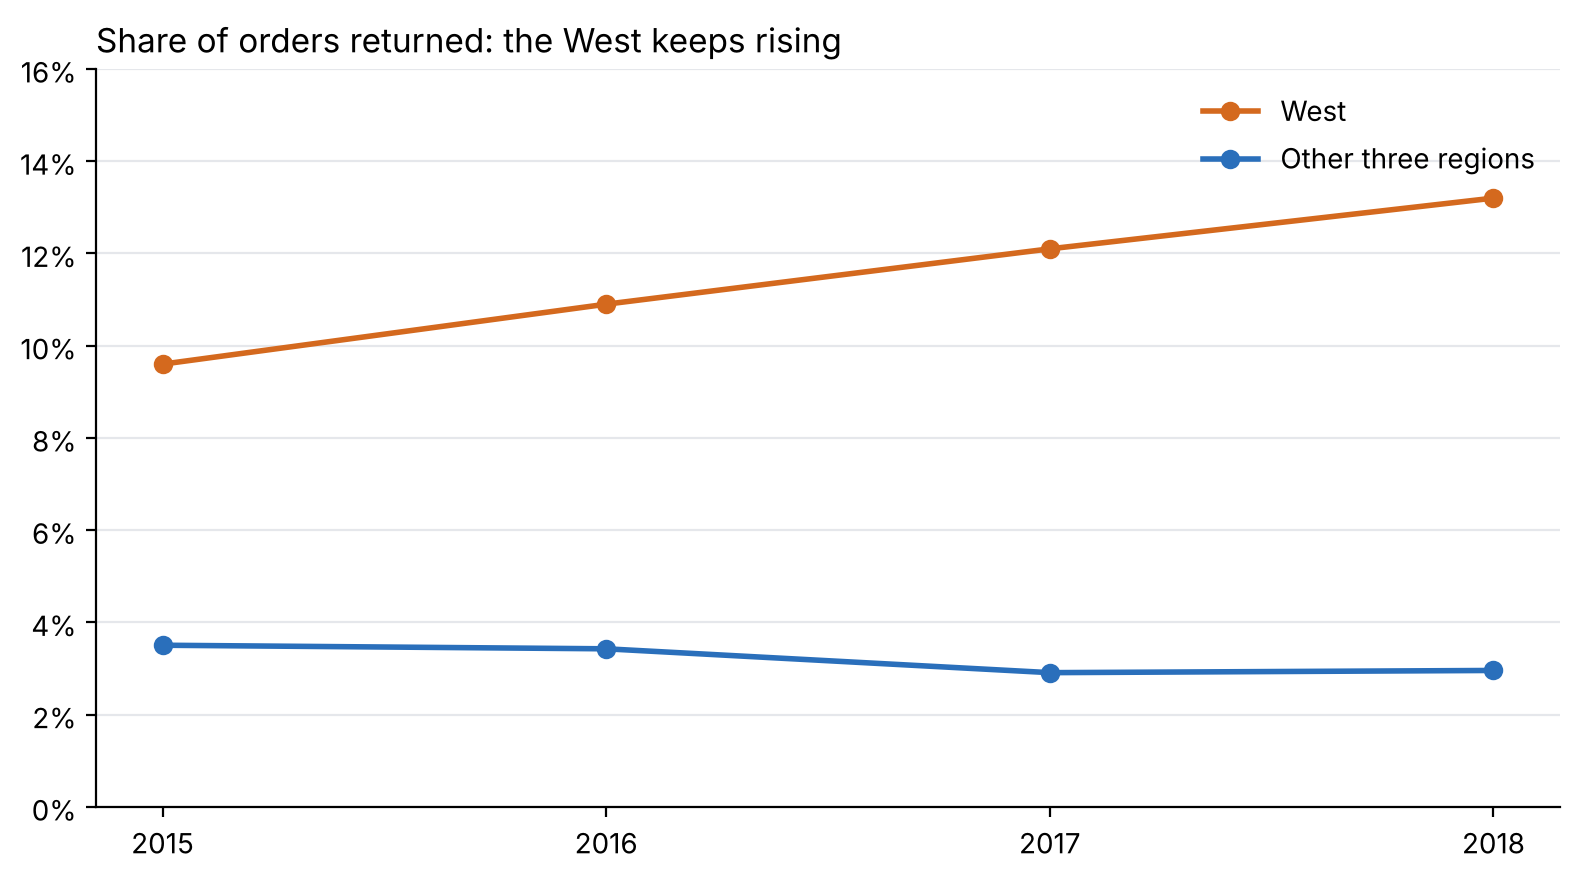

In [25]:
# Chart 4: return rate, West vs the other three regions
west = returns_by_year[returns_by_year["region"] == "West"].set_index("year")["return_rate_pct"]
others = returns_by_year[returns_by_year["region"] != "West"].groupby("year")[["returned_orders", "orders"]].sum()
others_rate = 100 * others["returned_orders"] / others["orders"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(west.index, west.values, color=ORANGE, linewidth=2, marker="o", label="West")
ax.plot(others_rate.index, others_rate.values, color=BLUE, linewidth=2, marker="o", label="Other three regions")
ax.set_xticks(list(west.index))
ax.set_ylim(0, 16)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0f}%")
ax.set_title("Share of orders returned: the West keeps rising", loc="left")
ax.legend(frameon=False)
tidy(ax)
fig.tight_layout()
fig.savefig("../dashboard/analysis_return_rate.png", dpi=150)
plt.show()

In [26]:
conn.close()